# ds_charts - example gallery

Every chart in the library, drawn from **synthetic** data (`ds_charts.synthetic`). Use it to see what each chart
looks like and exactly which columns it needs. Replace `T[...]` with your own tables of the same shape.

In [1]:
import sys, matplotlib.pyplot as plt
sys.path.insert(0, ".")              # the folder that contains ds_charts/
import ds_charts as dc
from ds_charts.synthetic import make_example_tables

T = make_example_tables()
SEGS, SEG_LABELS, SEG_MEANS = T["segments"], T["seg_labels"], T["seg_means"]
UNIT = dc.Units("$", "per order")    # or dc.Units("orders", "per year")
OUT = "example_charts"               # PNGs land here; None = do not save
T["effects"].head()

,feature,label,segment,effect,p10_p90,verdict,p
0,pickup_share,Pickup share of orders,SEG_MID,1.8,4.790350,SHIP,0.000001
1,pickup_share,Pickup share of orders,SEG_HIGH,3.9,10.295254,SHIP,0.000001
2,pages_per_visit,Pages per visit,SEG_MID,2.6,6.504110,SHIP,0.000001
3,pages_per_visit,Pages per visit,SEG_HIGH,5.1,12.680503,SHIP,0.000001
4,channels_used,Fulfilment channels used,SEG_MID,1.5,3.849196,SHIP,0.000001


## 1. What moves the outcome: +1 SD effect, both segments (SHIP levers only)

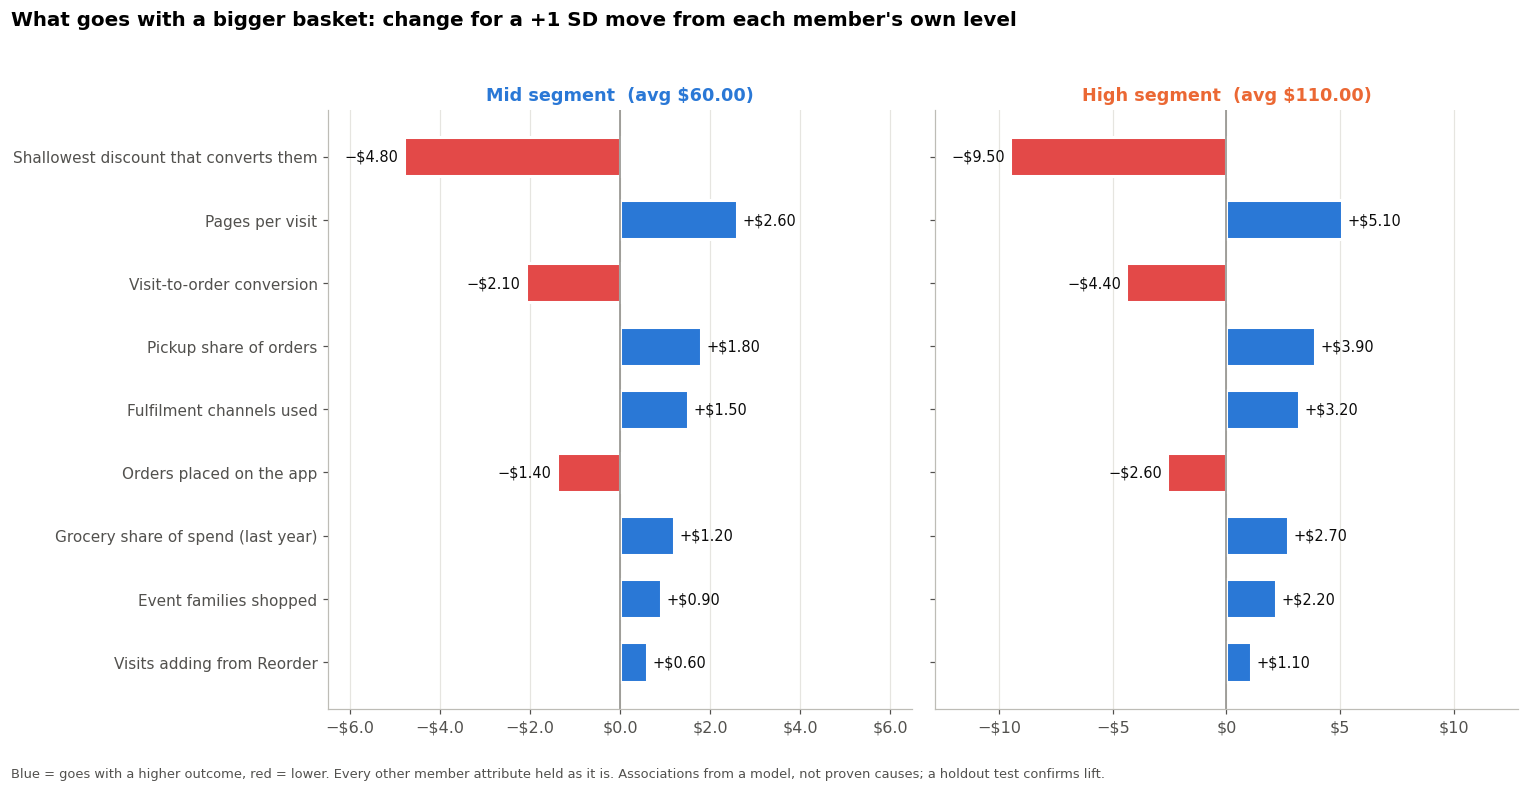

In [2]:
dc.effect_bars(T["effects"], SEGS, UNIT, seg_labels=SEG_LABELS, seg_means=SEG_MEANS,
               title="What goes with a bigger basket", out_dir=OUT, name="1_effect_bars_1sd"); plt.show()

## 1b. Same chart on the p10 → p90 swing

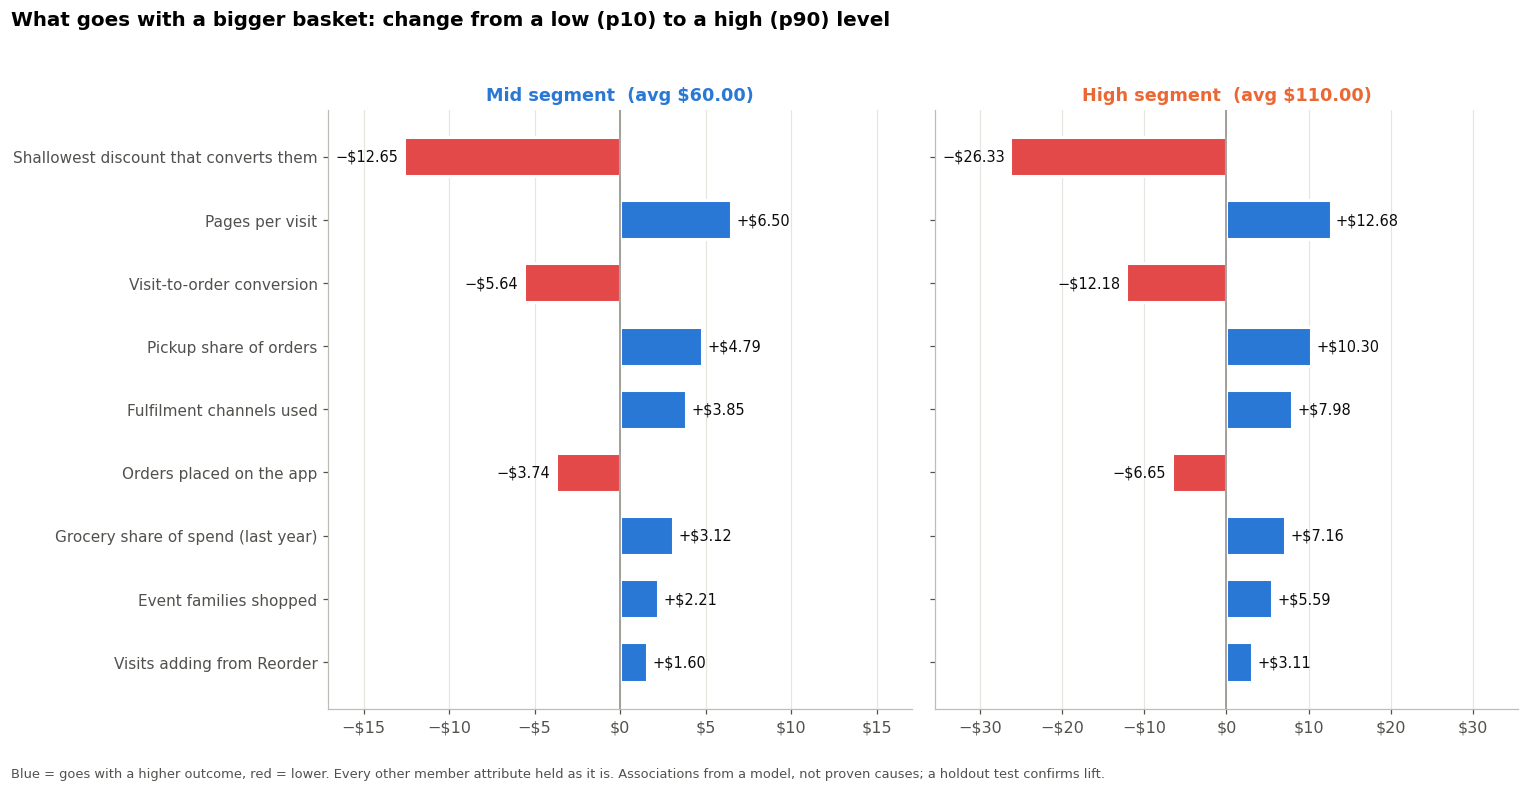

In [3]:
dc.effect_bars(T["effects"], SEGS, UNIT, value_col="p10_p90", seg_labels=SEG_LABELS, seg_means=SEG_MEANS,
               title="What goes with a bigger basket", metric_note="change from a low (p10) to a high (p90) level",
               out_dir=OUT, name="1b_effect_bars_p10_p90"); plt.show()

## 1c. One segment, slide-ready

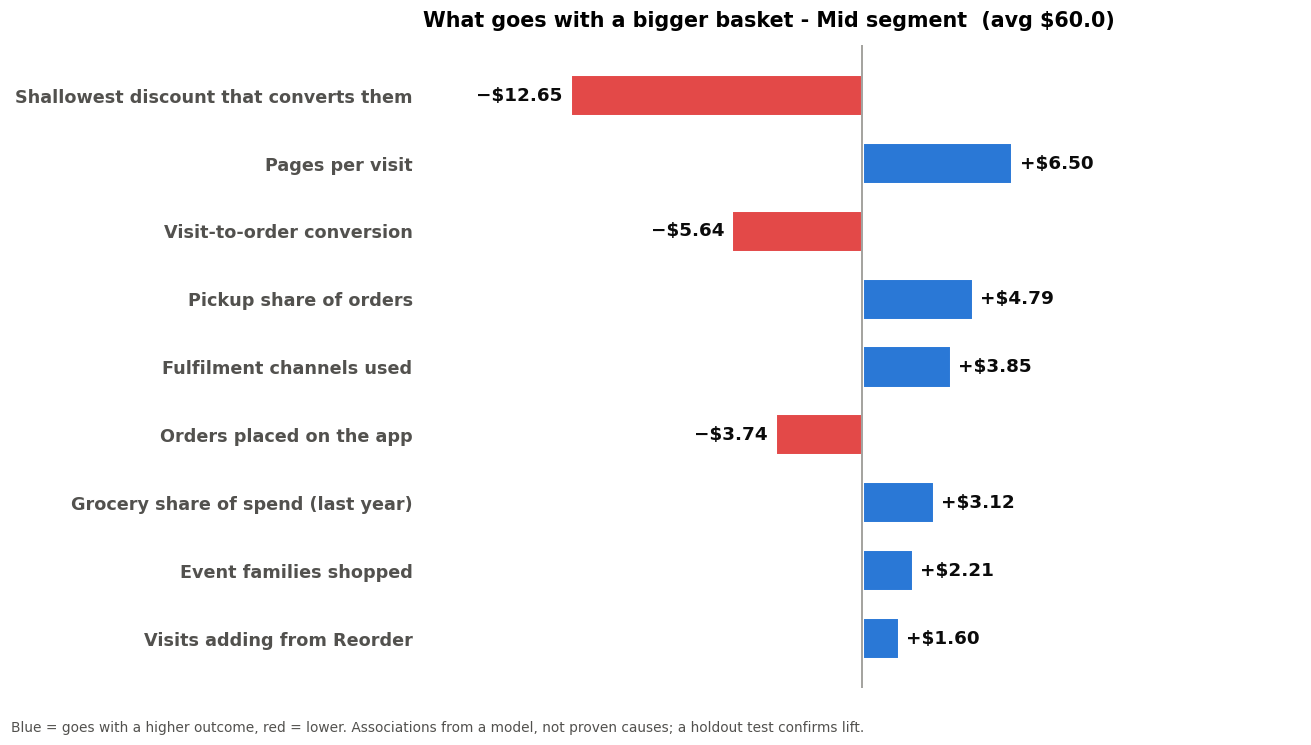

In [4]:
dc.effect_bars_single(T["effects"], "SEG_MID", UNIT, value_col="p10_p90", seg_label="Mid segment",
                      seg_mean=SEG_MEANS["SEG_MID"], title="What goes with a bigger basket",
                      out_dir=OUT, name="1c_effect_bars_single"); plt.show()

## 2. Every lever, recommended and held (held in grey)

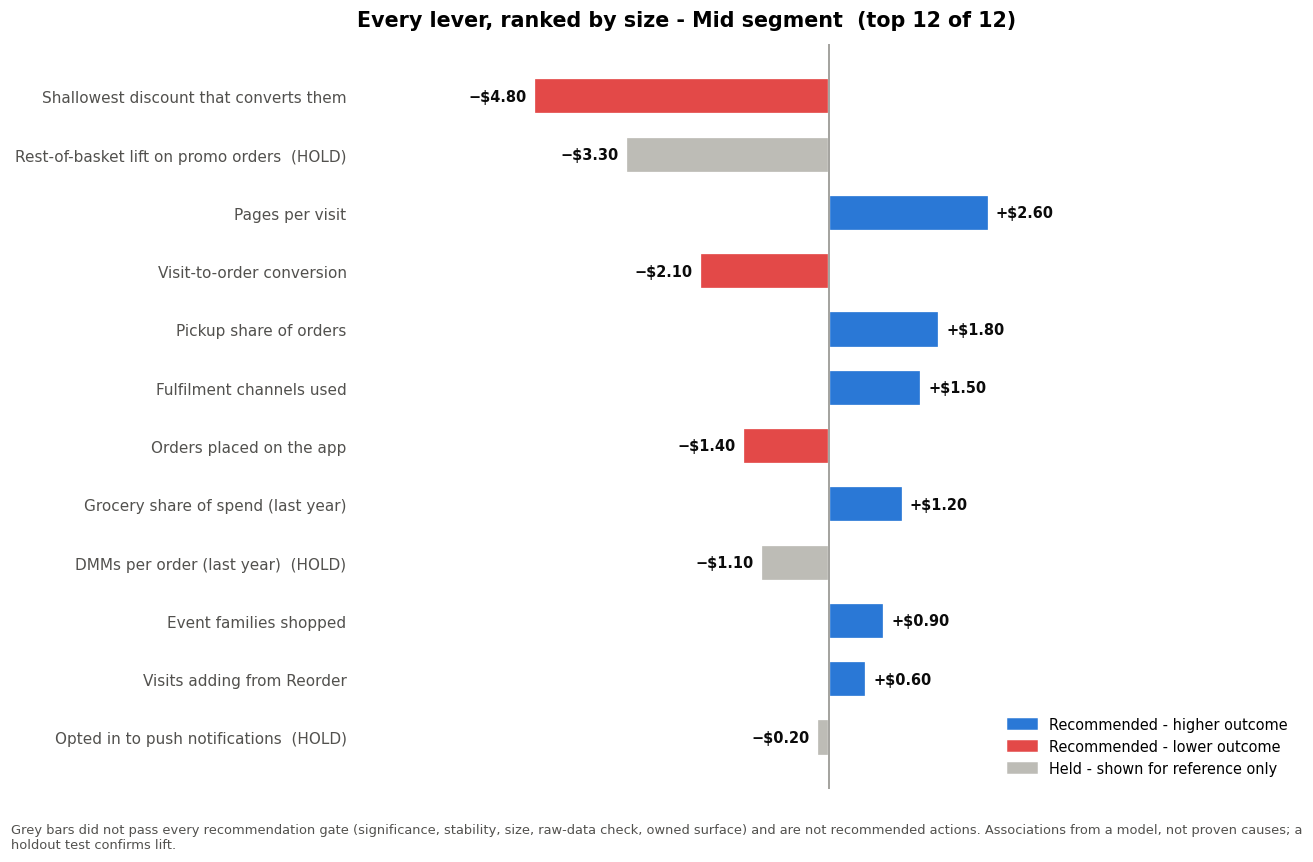

In [5]:
dc.ranking_bars(T["effects"], "SEG_MID", UNIT, seg_label="Mid segment", out_dir=OUT, name="2_ranking_bars"); plt.show()

## 3. Marginal-effect curves, one per lever (SHIP levers in effect order)

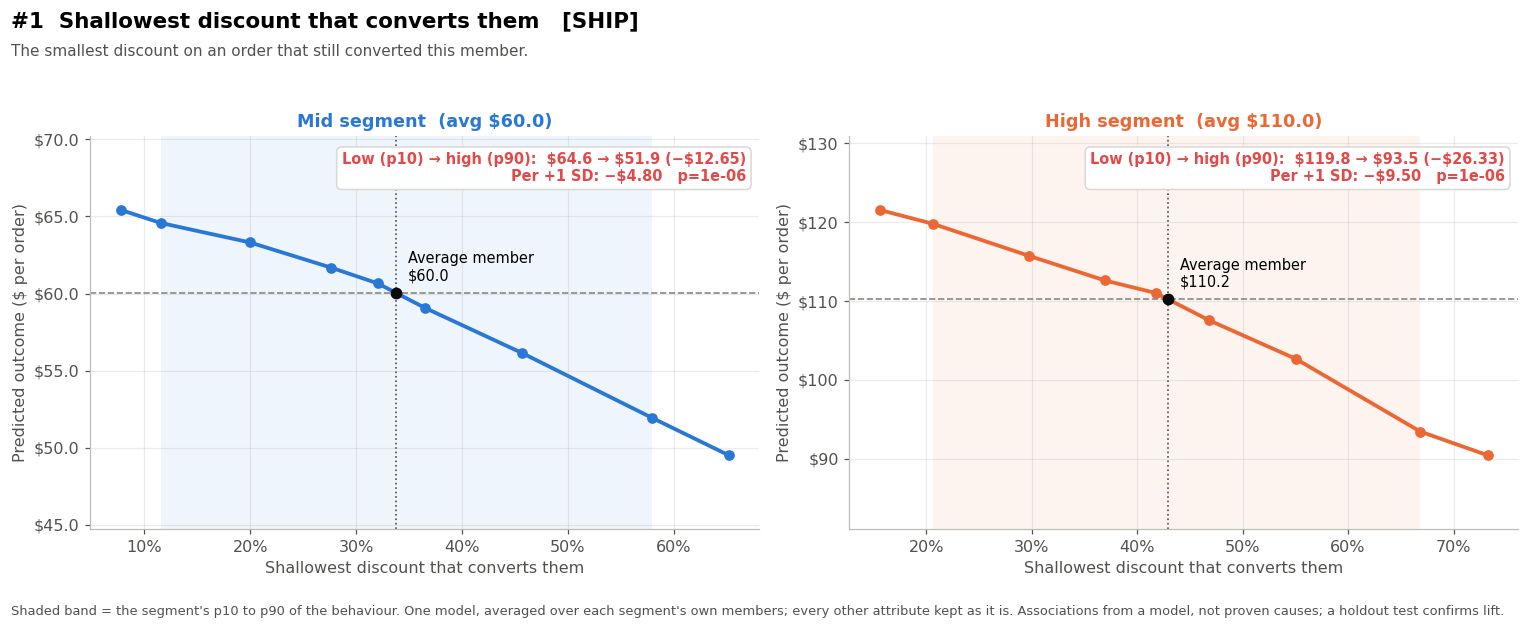

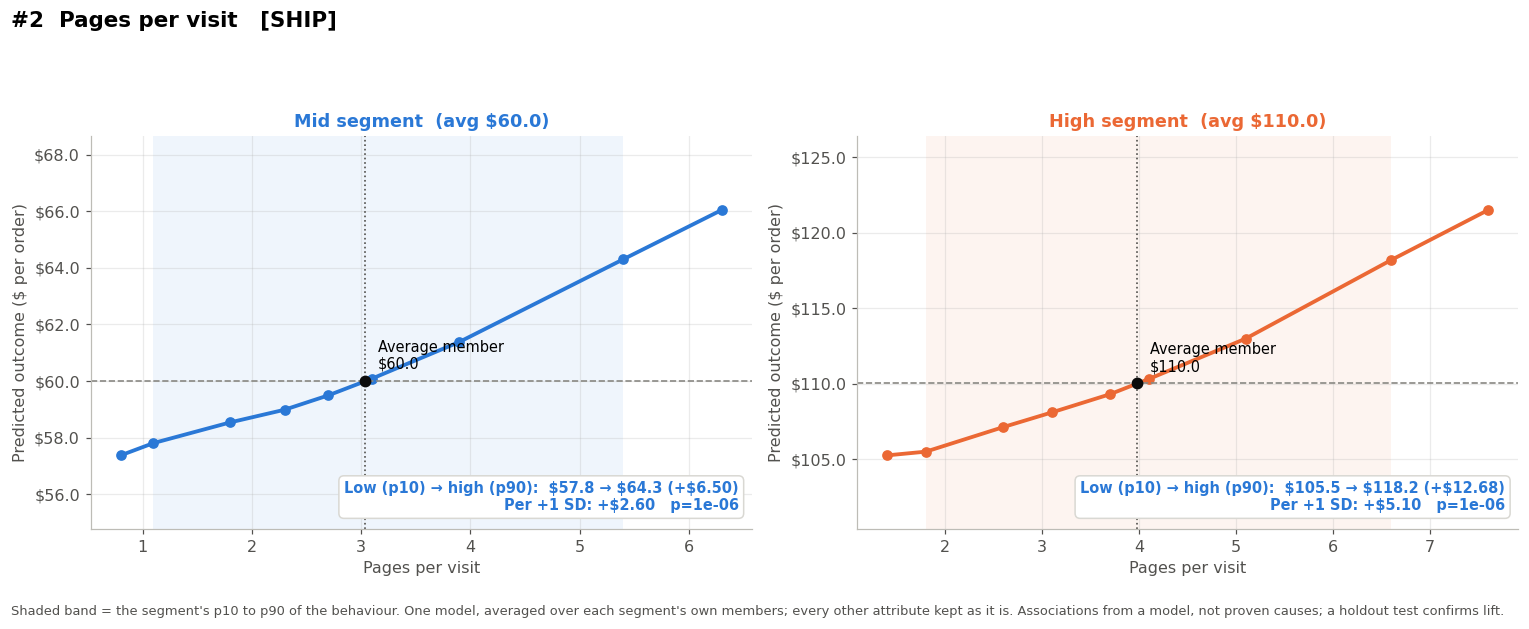

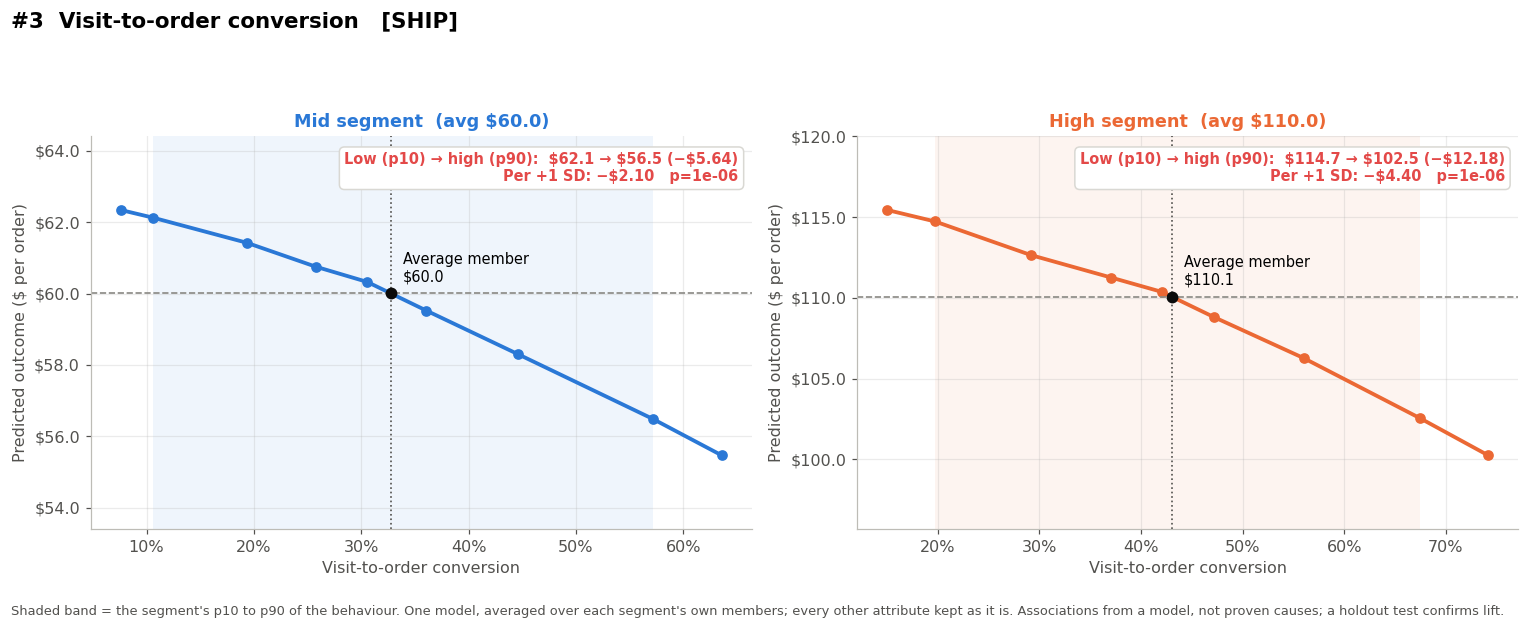

[<Figure size 1540x594 with 2 Axes>,
 <Figure size 1540x594 with 2 Axes>,
 <Figure size 1540x594 with 2 Axes>]

In [6]:
ship = (T["effects"][T["effects"].verdict == "SHIP"].query("segment == 'SEG_MID'")
        .assign(a=lambda d: d.p10_p90.abs()).sort_values("a", ascending=False))
labels = dict(zip(T["effects"].feature, T["effects"].label))
dc.marginal_curves(T["curves"], T["summary"], ship.feature.head(3), SEGS, UNIT, labels=labels,
                   verdicts={f: "SHIP" for f in ship.feature}, seg_labels=SEG_LABELS, seg_means=SEG_MEANS,
                   explanations={"discount_floor": "The smallest discount on an order that still converted this member."},
                   out_dir=OUT)

## 4. What predicts the outcome - all features, context vs lever

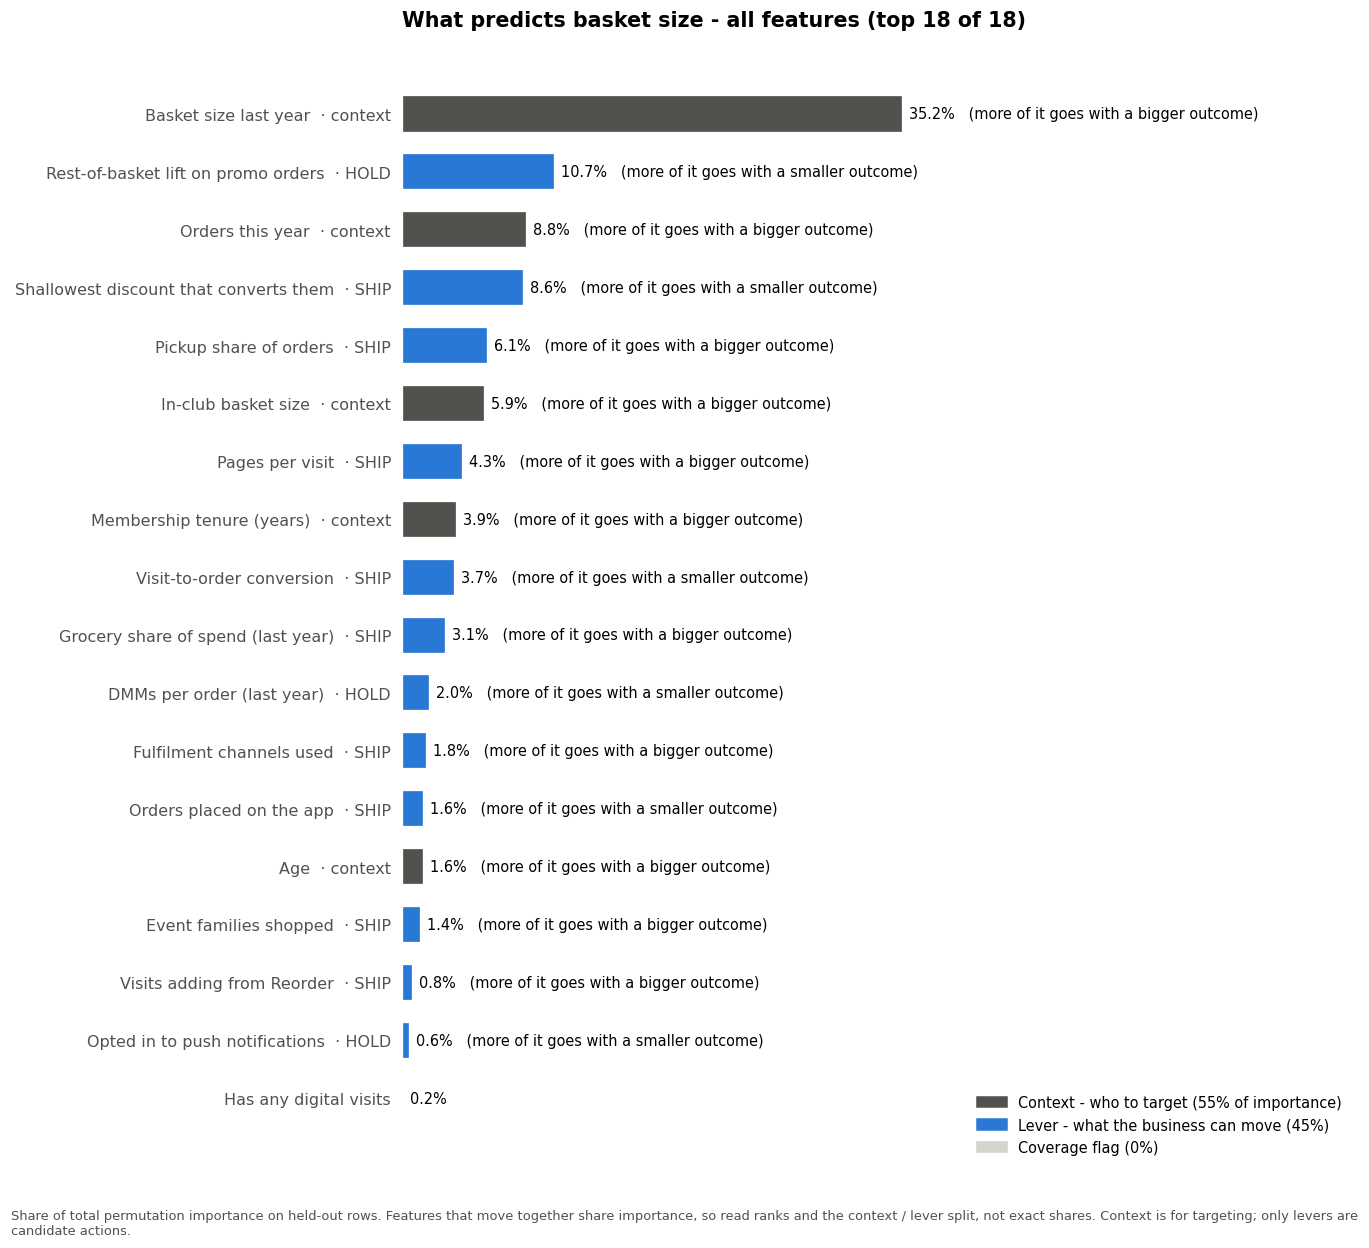

In [7]:
dc.importance_bars(T["importance"], outcome="basket size", out_dir=OUT, name="4_importance_all"); plt.show()

## 5. Model fit within each segment

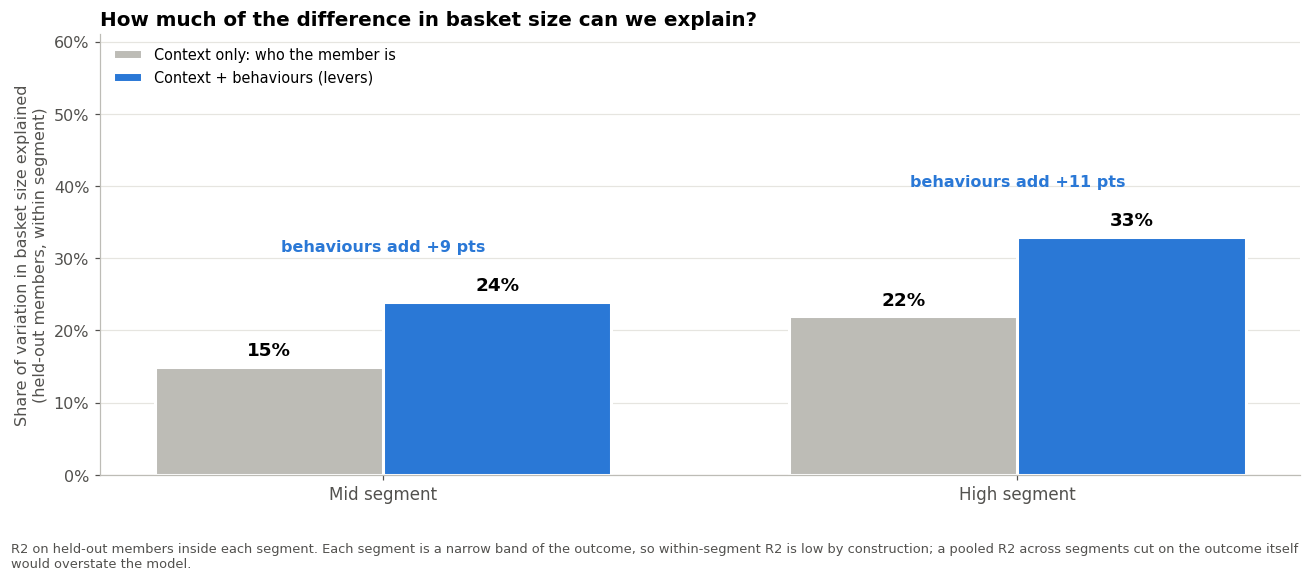

In [8]:
dc.fit_bars(T["fit"], outcome="basket size", seg_labels=SEG_LABELS, out_dir=OUT, name="5_model_fit"); plt.show()

## 6. Where the gap sits, by category (arithmetic, no model)

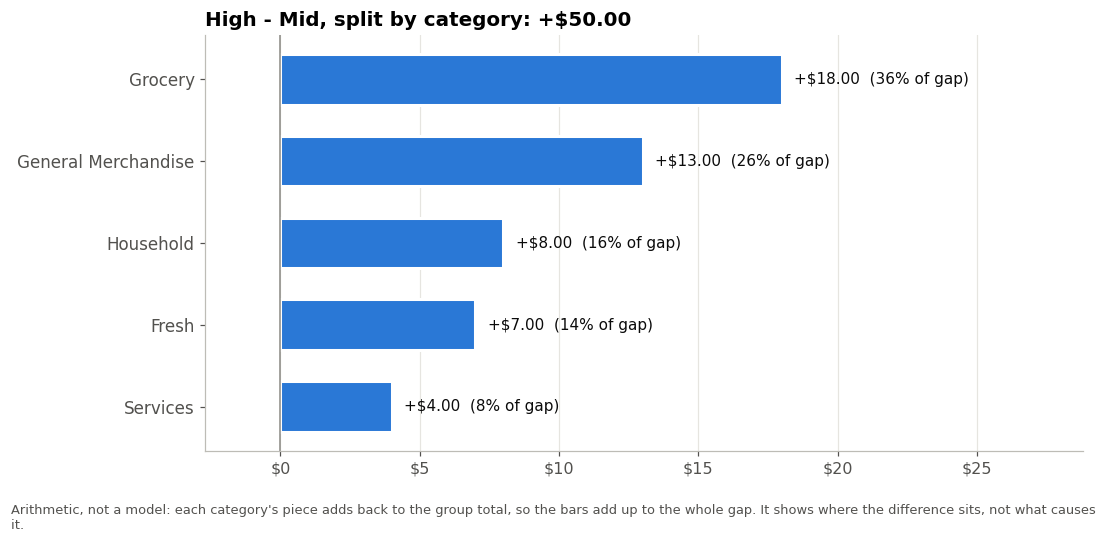

In [9]:
dc.gap_bars(T["gap"], UNIT, low_name="Mid", high_name="High", out_dir=OUT, name="6_gap_by_category"); plt.show()

## 7. Scorecard - notebook table and slide image

In [10]:
dc.scorecard_table(T["scorecard"], UNIT, seg_names=("Mid", "High"))

behaviour,feature,effect Mid,effect High,p,verdict,action
Orders placed on the app,app_order_share,−$1.40,−$2.60,1e-06,SHIP,App basket builder before checkout
Fulfilment channels used,channels_used,+$1.50,+$3.20,1e-06,SHIP,Introduce a second fulfilment option
Visit-to-order conversion,conversion_rate,−$2.10,−$4.40,1e-06,SHIP,Basket threshold on quick top-up orders
Shallowest discount that converts them,discount_floor,−$4.80,−$9.50,1e-06,SHIP,Spend-threshold offers instead of deeper discounts
DMMs per order (last year),dmm_per_order_ly,−$1.10,−$2.30,0.2,HOLD - opposite sign to the raw data,Cross-department prompts
Event families shopped,event_families,+$0.90,+$2.20,1e-06,SHIP,Cross-event bundles
Grocery share of spend (last year),grocery_share_ly,+$1.20,+$2.70,1e-06,SHIP,Bulk-pack and multi-buy grocery offers
Pages per visit,pages_per_visit,+$2.60,+$5.10,1e-06,SHIP,Curated collections and recommendations
Pickup share of orders,pickup_share,+$1.80,+$3.90,1e-06,SHIP,Pickup basket builder and a spend threshold on pickup orders
Rest-of-basket lift on promo orders,promo_lift,−$3.30,−$6.10,0.2,HOLD - opposite sign to the raw data,Pair the deal with a complementary item


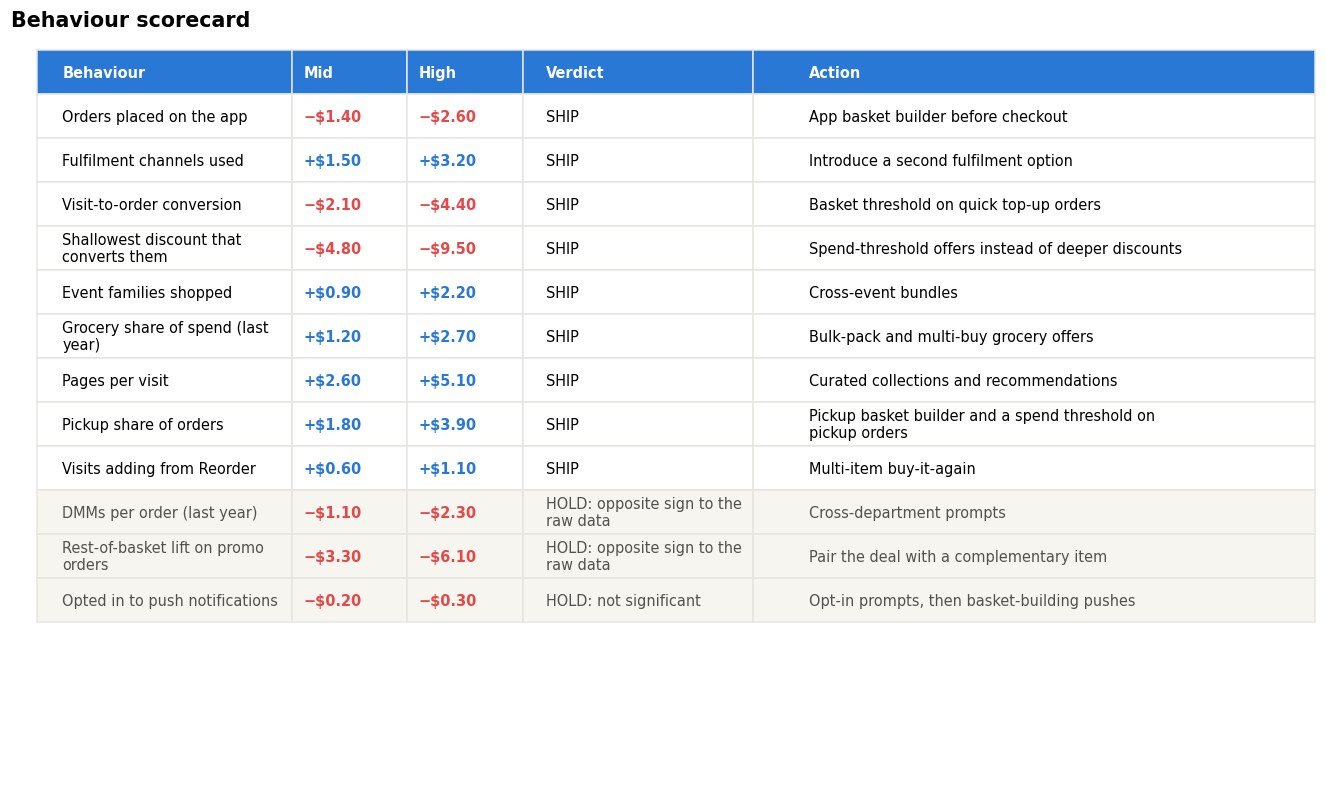

In [11]:
dc.scorecard_figure(T["scorecard"], UNIT, seg_names=("Mid", "High"), out_dir=OUT, name="7_scorecard"); plt.show()

## 8. Where the segments sit on the top behaviours

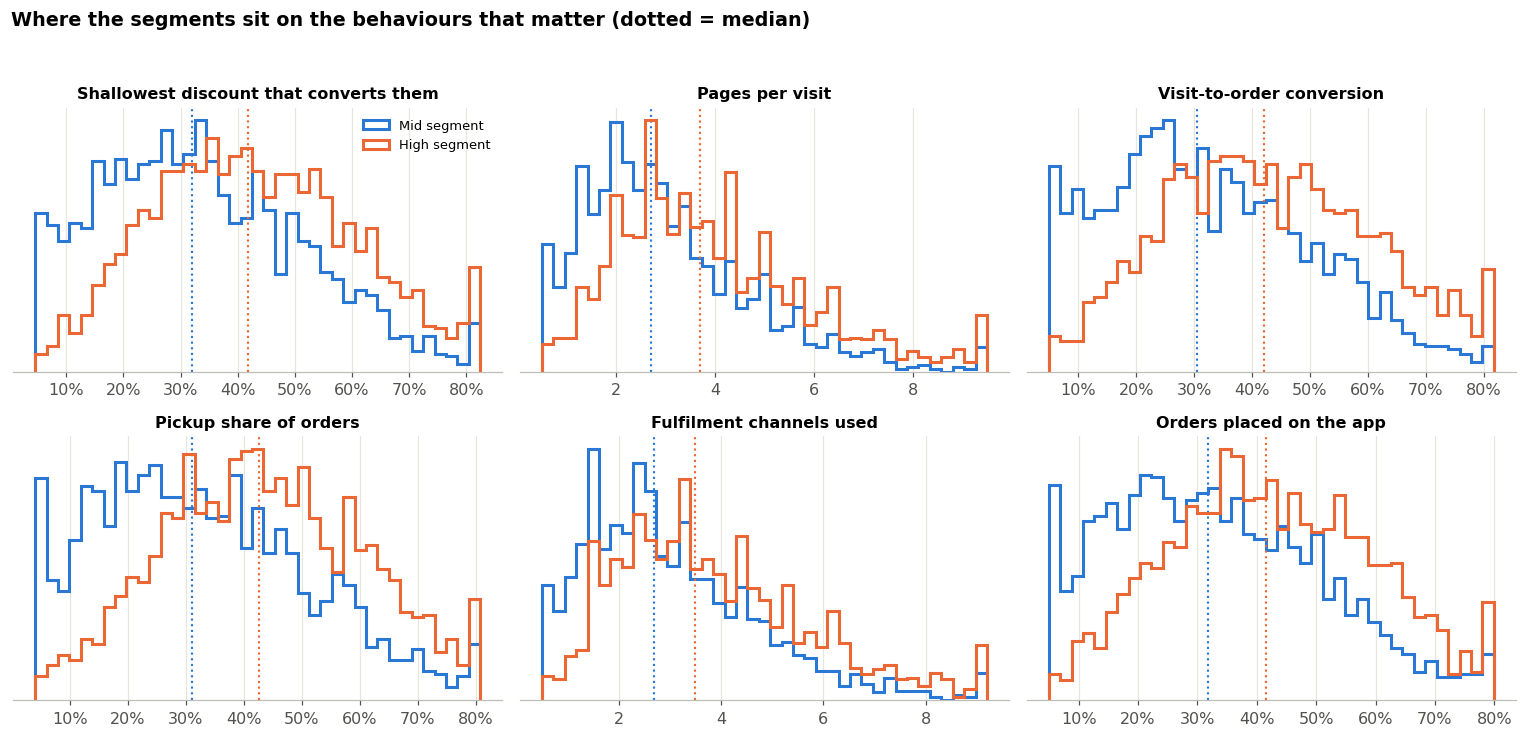

In [12]:
dc.segment_distributions(T["frame"], ship.feature.head(6), SEGS, labels=labels, seg_labels=SEG_LABELS,
                         out_dir=OUT, name="8_distributions"); plt.show()